# Day 1 lab: Applied Lab 1 — Data exploration

<p class="lead">
Explore more than 50,000 diamonds for a jewellery retailer: inspect the table and its data quality, compare average prices across cut and colour grades with a pivot table, and read a correlation heatmap, a violin plot and a hexbin plot. Then explain in your own words what drives diamond prices, and why one summary table seems to contradict common sense.
</p>

*Adapted from the DATA 300 syllabus, Applied Lab 1 (Data Exploration), for local Jupyter without internet access.*

| | |
|---|---|
| **Graded** | Yes: **3%** of the course grade |
| **Outcomes** | CLO 1, 2 and 3 |
| **Tool** | JupyterLab (Anaconda) |
| **You submit** | One PDF, `YourLastName_DATA300_AppliedLab1.pdf`, in the **Applied Lab 1** drop-box on **GAP (Moodle)** |
| **Deadline** | End of today, 23:59 China Standard Time, unless your facilitator says otherwise (see the [schedule](schedule.md)) |

---

## The business scenario

You are a data analyst at **LuxeGems**, an international jewellery retailer. The purchasing team wants to buy diamonds at competitive prices without giving up margin. They have sent you a table of more than 50,000 diamonds with their physical attributes and retail prices in **US dollars**:

| Column | Meaning |
|---|---|
| `carat` | Weight (1 carat = 0.2 grams) |
| `cut` | Quality of the cut, from **Fair** (lowest) through Good, Very Good and Premium to **Ideal** (highest) |
| `color` | Colour grade, from **D** (colourless, best) to **J** (slightly yellow, lowest) |
| `clarity` | How free the stone is of flaws, from I1 (lowest) to IF (flawless) |
| `depth`, `table` | Proportions of the cut stone, in per cent |
| `x`, `y`, `z` | Length, width and depth in millimetres |
| `price` | Retail price (US dollars) |

Your job is to explore the raw data, judge its quality, see how the attributes relate to price, and explain one result that looks wrong at first sight. This is **descriptive** and **diagnostic** analytics: what is in the data, and why does it look the way it does?

### Before you start

1. Keep this notebook in the course folder, next to the `data` folder.
2. Save your own copy: **File → Save Notebook As…** and type `YourLastName_Data300_AppliedLab1.ipynb` (with your real last name). Work in that copy.
3. The code below works as given. Run each cell in order with **Shift + Enter**, read the output, and answer the questions in Part 5. You may add cells of your own to check an answer.

---

## Part 1: Load the libraries and the data

Everything needed is part of Anaconda, so nothing is installed. The data loads from the `data` folder, without internet.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

diamonds = pd.read_csv("data/diamonds.csv")

cut_order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]   # lowest to highest quality
color_order = ["D", "E", "F", "G", "H", "I", "J"]               # best to lowest grade

print("Rows and columns:", diamonds.shape)
diamonds.head()

Rows and columns: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


---

## Part 2: Structural inspection and data quality

Before any analysis, check the size of the table, the type of each column, whether values are missing, and the range of each number.

In [2]:
print("--- Dataset information ---")
diamonds.info()

print("\n--- Missing values per column ---")
print(diamonds.isnull().sum())

print("\n--- Descriptive statistics (numeric columns) ---")
diamonds.describe().round(2)

--- Dataset information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB

--- Missing values per column ---
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

--- Descriptive statistics (numeric columns) ---


,carat,depth,table,price,x,y,z
count,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00
mean,0.80,61.75,57.46,3932.80,5.73,5.73,3.54
std,0.47,1.43,2.23,3989.44,1.12,1.14,0.71
min,0.20,43.00,43.00,326.00,0.00,0.00,0.00
25%,0.40,61.00,56.00,950.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,2401.00,5.70,5.71,3.53
75%,1.04,62.50,59.00,5324.25,6.54,6.54,4.04
max,5.01,79.00,95.00,18823.00,10.74,58.90,31.80


> **Look closely**
>
> Use the outputs above for questions 1 and 2. In the statistics table, also read the `min` row for `x`, `y` and `z`. Is every value physically possible for a real stone? (You are not asked to fix anything; noting it is good analytical practice.)

---

## Part 3: Pivot table — average price by cut and colour

A pivot table compares one measure across two categories. Here: the **average price** with **cut** in the rows and **colour** in the columns. `.reindex(cut_order)` lists the cuts from Fair to Ideal instead of alphabetically.

In [3]:
price_pivot = pd.pivot_table(
    data=diamonds,
    values="price",
    index="cut",
    columns="color",
    aggfunc="mean",
).reindex(cut_order)

print("--- Average diamond price (US dollars) by cut quality and colour grade ---")
price_pivot.round(2)

--- Average diamond price (US dollars) by cut quality and colour grade ---


color,D,E,F,G,H,I,J
cut,,,,,,,
Fair,4291.06,3682.31,3827.00,4239.25,5135.68,4685.45,4975.66
Good,3405.38,3423.64,3495.75,4123.48,4276.25,5078.53,4574.17
Very Good,3470.47,3214.65,3778.82,3872.75,4535.39,5255.88,5103.51
Premium,3631.29,3538.91,4324.89,4500.74,5216.71,5946.18,6294.59
Ideal,2629.09,2597.55,3374.94,3720.71,3889.33,4451.97,4918.19


Use this table for questions 3 and 4. Read the column for colour **E** from the Fair row to the Ideal row. Is that the order you would expect?

---

## Part 4: Visualising more than 50,000 diamonds

A plain scatter plot of 50,000 points becomes an unreadable blob. Three charts handle this better:

| Chart | Shows |
|---|---|
| **Correlation heatmap** | The straight-line relationship between every pair of numeric columns, from −1 to +1 |
| **Violin plot** | The full shape of the price distribution within each cut |
| **Hexbin plot** | Where the diamonds are concentrated when carat is plotted against price |

### 4.1 Correlation heatmap

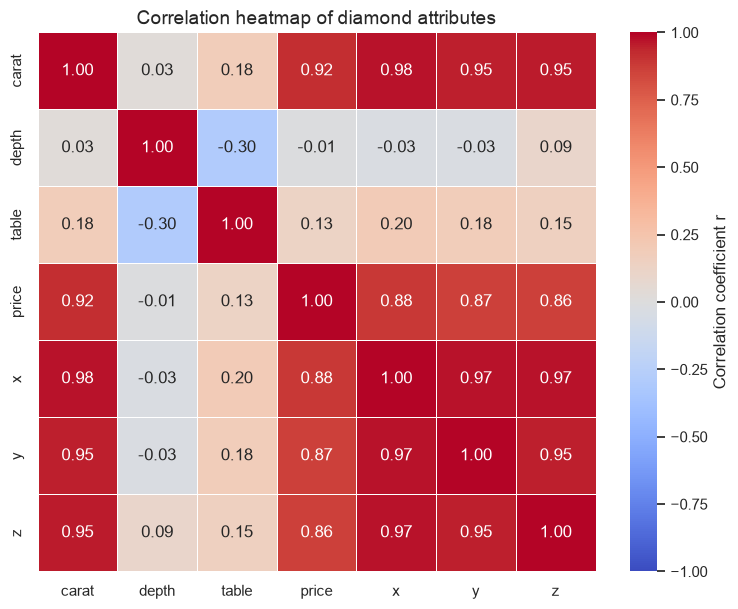

In [4]:
sns.set_theme(style="whitegrid")

numeric_cols = diamonds.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
    linewidths=0.5, vmin=-1, vmax=1,
    cbar_kws={"label": "Correlation coefficient r"},
)
plt.title("Correlation heatmap of diamond attributes", fontsize=14)
plt.show()

### 4.2 Violin plot: price by cut quality

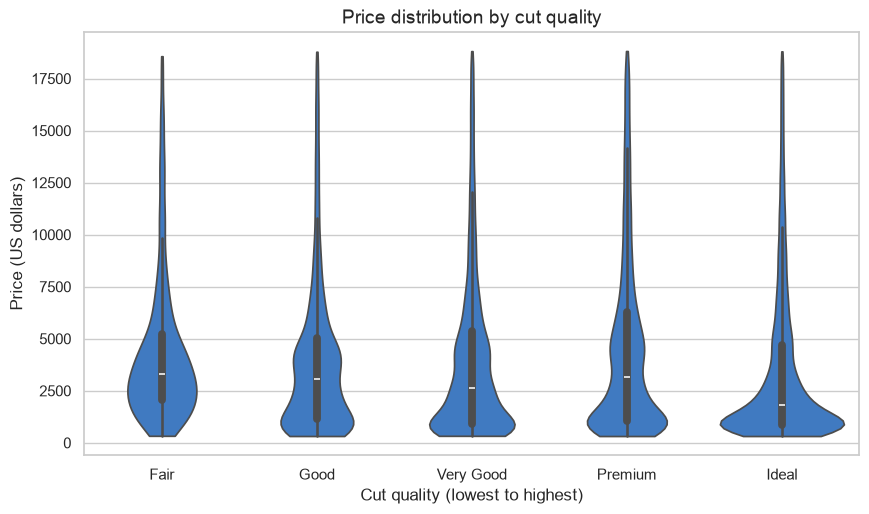

In [5]:
plt.figure(figsize=(10, 5.5))
sns.violinplot(data=diamonds, x="cut", y="price", order=cut_order, color="#2a78d6", cut=0)
plt.title("Price distribution by cut quality", fontsize=14)
plt.xlabel("Cut quality (lowest to highest)")
plt.ylabel("Price (US dollars)")
plt.show()

### 4.3 Hexbin density plot: carat against price

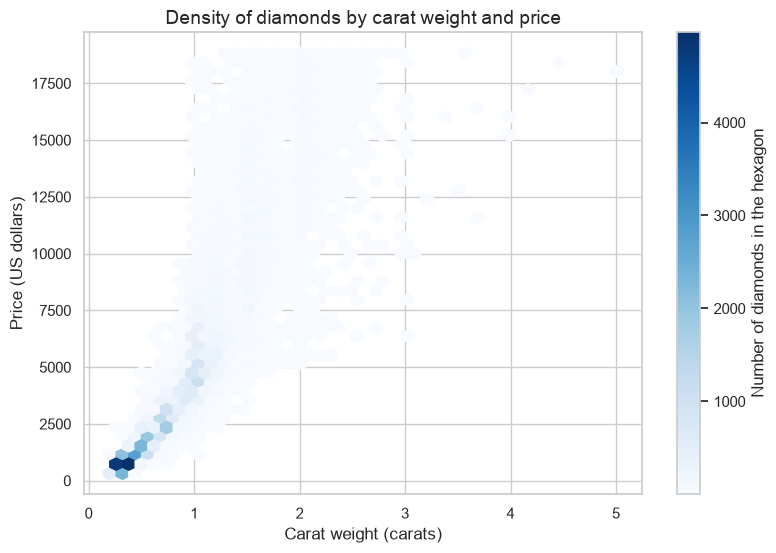

In [6]:
plt.figure(figsize=(9, 6))
plt.hexbin(diamonds["carat"], diamonds["price"], gridsize=40, cmap="Blues", mincnt=1)
plt.colorbar(label="Number of diamonds in the hexagon")
plt.title("Density of diamonds by carat weight and price", fontsize=14)
plt.xlabel("Carat weight (carats)")
plt.ylabel("Price (US dollars)")
plt.show()

---

## Part 5: Questions

Answer **all six questions in complete sentences** in the answer cell below. Base every answer on the outputs in this notebook, and quote the numbers you use.

### Section A: Data quality and structure

| # | Question |
|---|---|
| **1** | How many rows (diamonds) and columns does the dataset have, according to Part 2? |
| **2** | Does any column have missing (null) values that would need cleaning before further analysis? Say how you can tell. |

### Section B: Pivot table and diagnosis

| # | Question |
|---|---|
| **3** | In the pivot table (Part 3), look at colour grade **E**. Which has the higher average price: **Fair** cut or **Ideal** cut? Give both values. |
| **4** | A better cut should be worth more, so why can Fair-cut diamonds show a higher average price than Ideal-cut diamonds in this table? Think about an attribute the table ignores, and name the general idea this illustrates. You may add a cell to check your explanation. |

### Section C: Correlation and charts

| # | Question |
|---|---|
| **5** | (a) In the heatmap (Part 4.1), which numeric attribute has the strongest positive correlation with `price`? State its correlation coefficient *r*. (b) In the violin plot (Part 4.2), are prices roughly symmetric (a bell shape) or strongly right-skewed? Where are most prices concentrated? |
| **6** | In the hexbin plot (Part 4.3), what does the darkest cluster tell LuxeGems about the diamonds in this data? Give the approximate **carat** range and **price** range where the diamonds are most concentrated. |

> **Writing tips**
>
> Lead with the answer, then the evidence: *"Most diamonds are small and cheap: the darkest hexagons lie between … and … carats and … and … dollars."* Name the chart or table you used. Keep units (US dollars, carats).

> **My answers**
>
> **Name:** *Your name* · **Student ID:** *Your ID*
>
> **1. Rows and columns:** *Your answer*
>
> **2. Missing values:** *Your answer*
>
> **3. Fair versus Ideal at colour E:** *Your answer*
>
> **4. Why Fair can look more expensive:** *Your answer*
>
> **5. (a) Strongest correlate of price and its r:** *Your answer*
>
> **5. (b) Shape of the price distribution:** *Your answer*
>
> **6. Densest region in the hexbin plot:** *Your answer*

---

## Going further (not graded)

If you have time, test your answer to question 4. The cell below compares cuts at colour **E** among diamonds of **almost the same weight**: three narrow windows around popular sizes. Holding weight nearly constant removes most of its effect, so any remaining gap is closer to the effect of the cut itself. The cell shows the average price in each window and, underneath, how many diamonds each average is based on.

In [7]:
e_grade = diamonds[diamonds["color"] == "E"]
windows = {"0.30-0.34 ct": (0.30, 0.34), "0.70-0.74 ct": (0.70, 0.74), "1.00-1.04 ct": (1.00, 1.04)}

average_price = {}
diamond_count = {}
for label, (low, high) in windows.items():
    same_size = e_grade[e_grade["carat"].between(low, high)]
    average_price[label] = same_size.groupby("cut")["price"].mean()
    diamond_count[label] = same_size.groupby("cut")["price"].count()

print("Colour E: average price (US dollars) by cut, for diamonds of almost the same weight")
print(pd.DataFrame(average_price).reindex(cut_order).round(0))
print()
print("Number of diamonds behind each average")
print(pd.DataFrame(diamond_count).reindex(cut_order))
print()
print("Colour E, all weights: average carat by cut")
print(e_grade.groupby("cut")["carat"].mean().reindex(cut_order).round(2))

Colour E: average price (US dollars) by cut, for diamonds of almost the same weight
           0.30-0.34 ct  0.70-0.74 ct  1.00-1.04 ct
cut                                                
Fair              722.0        2318.0        4475.0
Good              621.0        2572.0        5448.0
Very Good         682.0        2812.0        6096.0
Premium           781.0        2709.0        5906.0
Ideal             812.0        3023.0        6265.0

Number of diamonds behind each average
           0.30-0.34 ct  0.70-0.74 ct  1.00-1.04 ct
cut                                                
Fair                 10            27            61
Good                 96           110           178
Very Good           236           288           292
Premium             364           221           257
Ideal               997           350           217

Colour E, all weights: average carat by cut
cut
Fair         0.86
Good         0.75
Very Good    0.68
Premium      0.72
Ideal        0.58
Name: car

Compare Fair and Ideal **within** each weight window with the overall pivot table in Part 3, and look at the average carat of each cut. Does the ranking change once weight is held nearly constant? Which averages rest on so few diamonds that you would not trust them on their own? A natural next step, which you will meet on Day 4, is a regression model that adjusts for carat, colour and clarity at the same time.

---

## Part 6: Export and submit

### 1. Export to PDF

1. Choose **Kernel → Restart Kernel and Run All Cells**. Check that every table and all three charts appear, and that your answers are in the answer cell.
2. Choose **File → Print** (or Ctrl + P / Cmd + P).
3. Set the destination to **Save as PDF**. Under *More settings*, tick **Background graphics** so the heatmap, violin and hexbin colours are kept.
4. Save the file as **`YourLastName_DATA300_AppliedLab1.pdf`**, with your real last name.

### 2. Upload

Log in to **GAP (Moodle)**, open the **DATA 300: Applied Lab 1** drop-box, upload the PDF and click **Submit**.

---

## Checklist before you upload

- [ ] The notebook was **restarted and run all**; the dataset information, missing-value counts, statistics table and pivot table all appear.
- [ ] The heatmap, violin plot and hexbin plot appear, in colour.
- [ ] All six questions are answered in complete sentences, with the numbers you used.
- [ ] Your name and student ID are in the answer cell.
- [ ] The file is named `YourLastName_DATA300_AppliedLab1.pdf` and uploaded to the Applied Lab 1 drop-box on GAP (Moodle).

## How it is marked

The lab uses the course's lab rubric: **CLO 1** (describing descriptive analytics for a business problem, 25 points), **CLO 2** (using visualisation tools to communicate findings, 25 points), **CLO 3** (computational problem-solving to find relationships in the data, 30 points), **professional formatting** (10 points) and **clear academic writing** (10 points). In practice: all outputs present, correct answers supported by evidence from the outputs, a clear explanation of question 4, and a correctly named PDF.

> **Stuck?**
>
> `FileNotFoundError` means the notebook is not next to the `data` folder: move it into the course folder. For anything else, take a screenshot and ask your facilitator.